# PneumoLens · Phase 3 — Reproducible Image Preprocessing

**Production-oriented engineering notebook | Kaggle → GitHub → VS Code → Streamlit**

**Objective.** Freeze and verify a single *image-processing contract* for pediatric chest X-ray binary classification. It will be reused unchanged for training, validation, testing and application inference. This phase **does not train a model or create a validation split**.

**One-run design:** discover the exact `chest_xray` dataset → check source identity → export a real `src/preprocessing/transforms.py` module and versioned config → run safety/regression tests → run the deterministic transform over every original training image → visualize NORMAL/PNEUMONIA transforms and mild training-only augmentation → save evidence/limitations → package the correct project paths into one downloadable ZIP.

**Ethical boundary:** research/educational system only. Labels are not microbiological confirmation; this is not a clinical diagnostic tool.

> **Before running:** Attach the same Kaggle dataset as Phases 1–2. The prior observed source was `ZhangLabData/CellData/chest_xray`, nested under a larger X-ray + OCT package. Enable CPU or GPU as desired; **no GPU, internet, model weights, or pip install is needed**.

## 1 · Decisions, assumptions, and important gates

**Evidence from completed phases (not re-estimated here):** Phase 1 found 5,856 X-rays and 27 exact duplicate groups, plus an unresolved cross-split perceptual-similarity screen; Phase 2 profiled 5,232 original training images, preserved 624 original test images, found substantial native size/encoding differences across labels, and flagged 62 unique training images for human review. Neither phase verified patient identities or approved a validation split.

| Decision | Phase 3 contract |
|---|---|
| Input | 8-bit Pillow grayscale `L`; RGB source images are converted to luminance consistently |
| Geometry | 224×224; BILINEAR resize with **preserved aspect ratio and centered zero padding**; no crop |
| Model channels | The grayscale pixels are replicated to 3 channels for ImageNet-pretrained DenseNet121 |
| Normalization | **Fixed ImageNet-1K mean/std**, never computed from unapproved splits |
| Training-only augmentation | Up to ±5° rotation, ±2% translation, ±5% brightness and contrast |
| No flips | Horizontal and vertical flips, aggressive crops and perspective warps are disabled |
| Test and validation | Never used to select normalization, augmentation, or training weights; pixel checks use original train only |
| Class imbalance | A helper exists, but class weights may be calculated **only after approval of the future training subset** |

**Scope of Phase 3 completion:** portable source/config/test package + reproducible train-only numerical and visual checks. **Separate training-readiness gate:** still blocked by unverified patient/group independence and unresolved duplicate/split review. No Phase 3 output implies those issues were resolved.

In [1]:
from __future__ import annotations

import base64
import hashlib
import importlib.util
import io
import json
import os
import platform
import random
import re
import subprocess
import sys
import warnings
import zipfile
from collections import Counter
from contextlib import contextmanager
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath

import matplotlib
# Use Jupyter's inline backend for visible charts; figures are also saved to PNG.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps, ImageFile
from IPython.display import FileLink, display
from tqdm.auto import tqdm

# -------------- THE ONLY USER-CONFIGURABLE INPUTS --------------
INPUT_ROOT = Path(os.environ.get('PNEUMOLENS_INPUT_ROOT', '/kaggle/input'))
SOURCE_OVERRIDE = os.environ.get('PNEUMOLENS_CXR_SOURCE', '').strip()
WORK_DIR = Path(os.environ.get('PNEUMOLENS_PREPROCESS_OUTPUT', '/kaggle/working/pneumolens_phase03'))
SEED = 2026
REQUIRE_ALL_TRAIN_IMAGES = True  # deliberate fail-closed validation gate
EXPECTED = {('train','NORMAL'):1349, ('train','PNEUMONIA'):3883,
            ('test','NORMAL'):234, ('test','PNEUMONIA'):390}

# Optional synthetic-data QA mode, NOT for actual project conclusions.
if os.environ.get('PNEUMOLENS_SYNTHETIC_TEST', '') == '1':
    EXPECTED = {}

PROJECT_ROOT = WORK_DIR / 'project_files'
PHASE_DIR = PROJECT_ROOT / 'reports' / 'Phase 3'
FIG_DIR = PROJECT_ROOT / 'reports' / 'figures'
TAB_DIR = PROJECT_ROOT / 'reports' / 'tables'
PRIVATE_DIR = PROJECT_ROOT / 'data' / 'processed'
SRC_DIR = PROJECT_ROOT / 'src' / 'preprocessing'
CONF_DIR = PROJECT_ROOT / 'configs'
TEST_DIR = PROJECT_ROOT / 'tests'
FIXTURE_DIR = TEST_DIR / 'fixtures'
DOC_DIR = PROJECT_ROOT / 'docs'
for d in (WORK_DIR, PHASE_DIR, FIG_DIR, TAB_DIR, PRIVATE_DIR,
          SRC_DIR, CONF_DIR, TEST_DIR, FIXTURE_DIR, DOC_DIR):
    d.mkdir(parents=True, exist_ok=True)

ImageFile.LOAD_TRUNCATED_IMAGES = False
warnings.filterwarnings('error', category=Image.DecompressionBombWarning)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
plt.rcParams.update({'figure.dpi':115, 'savefig.dpi':170, 'font.size':10,
                     'axes.titlesize':12, 'axes.spines.right':False,
                     'axes.spines.top':False})
print('PneumoLens | Phase 3 image preprocessing')
print('Input root:', INPUT_ROOT, '| Output:', WORK_DIR)
print('Python:', sys.version.split()[0], 'PyTorch:', torch.__version__,
      'Pillow:', Image.__version__, 'NumPy:', np.__version__)

PneumoLens | Phase 3 image preprocessing
Input root: /kaggle/input | Output: /kaggle/working/pneumolens_phase03
Python: 3.13.16 PyTorch: 2.11.0+cu130 Pillow: 13.0.0 NumPy: 2.1.3


## 2 · Detect the actual chest X-ray source (exclude OCT)

Prefer the known source path; otherwise discover **exactly one** correctly structured `chest_xray/{train,test}/{NORMAL,PNEUMONIA}` directory or ZIP prefix. Do not silently select a different collection.

In [2]:
EXTENSIONS = {'.jpg','.jpeg','.png','.bmp','.tif','.tiff','.webp'}
SPLITS = {'train':'train','training':'train','test':'test','testing':'test',
          'val':'val','valid':'val','validation':'val'}
LABELS = {'normal':'NORMAL','pneumonia':'PNEUMONIA'}
SKIP_DIRS = {'oct','__macosx','.git','__pycache__','.ipynb_checkpoints'}


def _norm(s):
    return re.sub('[^a-z0-9]','',s.lower())


def _is_cxr(name):
    return _norm(name) in ('chestxray','chestxrays')


def _has_children(root, known):
    try:
        return any(x.is_dir() and x.name.lower() in known for x in root.iterdir())
    except OSError:
        return False


def _valid_cxr(root):
    if not root.is_dir() or not _has_children(root, SPLITS):
        return False
    try:
        return any(x.is_dir() and x.name.lower() in SPLITS and _has_children(x, LABELS)
                   for x in root.iterdir())
    except OSError:
        return False


def _relative_split_label(relative):
    components = [s.lower() for s in PurePosixPath(relative).parts[:-1]]
    split_names = [SPLITS[c] for c in components if c in SPLITS]
    label_names = [LABELS[c] for c in components if c in LABELS]
    return (split_names[-1] if split_names else 'UNKNOWN',
            label_names[-1] if label_names else 'UNKNOWN')


def _zip_prefixes(path):
    found = set()
    with zipfile.ZipFile(path) as z:
        for info in z.infolist():
            if info.is_dir() or PurePosixPath(info.filename).suffix.lower() not in EXTENSIONS:
                continue
            parts = PurePosixPath(info.filename).parts
            for k, segment in enumerate(parts[:-1]):
                if _is_cxr(segment):
                    rel = '/'.join(parts[k+1:])
                    spl, lab = _relative_split_label(rel)
                    if spl != 'UNKNOWN' and lab != 'UNKNOWN':
                        found.add('/'.join(parts[:k+1]) + '/')
    return sorted(found)


def discover_source():
    if SOURCE_OVERRIDE:
        path = Path(SOURCE_OVERRIDE).expanduser()
        if path.is_dir() and _valid_cxr(path):
            return {'kind':'folder','path':path,'prefix':''}
        if path.is_file() and zipfile.is_zipfile(path):
            pfx = _zip_prefixes(path)
            if len(pfx) == 1:
                return {'kind':'zip','path':path,'prefix':pfx[0]}
        raise ValueError('PNEUMOLENS_CXR_SOURCE must reference one valid CXR tree or ZIP.')
    known = (INPUT_ROOT / 'datasets' / 'srabondcosta' / 'pneumonia' /
             'ZhangLabData' / 'CellData' / 'chest_xray')
    if _valid_cxr(known):
        return {'kind':'folder','path':known,'prefix':''}
    if not INPUT_ROOT.exists():
        raise FileNotFoundError(f'{INPUT_ROOT}: dataset not attached. Add the Kaggle source.')
    folders = []
    archives = []
    if _is_cxr(INPUT_ROOT.name) and _valid_cxr(INPUT_ROOT):
        folders.append(INPUT_ROOT)
    for base, subdirs, filenames in os.walk(INPUT_ROOT):
        subdirs[:] = [d for d in subdirs if d.lower() not in SKIP_DIRS
                      and not d.lower().startswith('oct') and not d.startswith('.')]
        parent = Path(base)
        if _is_cxr(parent.name) and _valid_cxr(parent):
            folders.append(parent)
            subdirs[:] = []
            continue
        for name in filenames:
            if name.lower().endswith('.zip'):
                archives.append(parent / name)
    folders = sorted(set(folders), key=str)
    if len(folders) == 1:
        return {'kind':'folder','path':folders[0],'prefix':''}
    if len(folders) > 1:
        raise ValueError('Multiple CXR trees found; choose one using PNEUMOLENS_CXR_SOURCE: ' +
                         ' | '.join(str(x) for x in folders))
    archive_sources = []
    for archive in sorted(archives, key=str):
        try:
            archive_sources.extend((archive,p) for p in _zip_prefixes(archive))
        except (OSError,zipfile.BadZipFile):
            continue
    if len(archive_sources) == 1:
        path,pfx = archive_sources[0]
        return {'kind':'zip','path':path,'prefix':pfx}
    if not archive_sources:
        raise FileNotFoundError('No compatible chest_xray dataset found; attach the same source as Phases 1–2.')
    raise ValueError('Multiple zipped CXR sources. Set PNEUMOLENS_CXR_SOURCE to one ZIP.')

SOURCE = discover_source()
ARCHIVE = zipfile.ZipFile(SOURCE['path']) if SOURCE['kind'] == 'zip' else None

@contextmanager
def open_image_bytes(rel):
    if ARCHIVE is None:
        with (SOURCE['path'] / Path(rel)).open('rb') as h:
            yield h
    else:
        with ARCHIVE.open(SOURCE['prefix'] + rel.replace('\\','/'), 'r') as h:
            yield h

print('Selected:', SOURCE['kind'], SOURCE['path'], '| ZIP prefix:', SOURCE['prefix'])

Selected: folder /kaggle/input/datasets/srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray | ZIP prefix: 


## 3 · Inventory and reconcile source identity

Only original train images will be decoded for preprocessing decisions. Original test rows are recorded by paths/labels/counts, **not used for normalization, augmentation, image galleries, or model tuning**.

In [3]:
records = []
if ARCHIVE is None:
    items = sorted((p for p in SOURCE['path'].rglob('*')
                    if p.is_file() and p.suffix.lower() in EXTENSIONS), key=str)
    for p in items:
        rel = p.relative_to(SOURCE['path']).as_posix()
        split, label = _relative_split_label(rel)
        records.append((rel,split,label,int(p.stat().st_size)))
else:
    for info in sorted(ARCHIVE.infolist(),key=lambda x:x.filename):
        if info.is_dir() or not info.filename.startswith(SOURCE['prefix']):
            continue
        rel = info.filename[len(SOURCE['prefix']):]
        if PurePosixPath(rel).suffix.lower() in EXTENSIONS and '__MACOSX' not in rel:
            split,label = _relative_split_label(rel)
            records.append((rel,split,label,int(info.file_size)))

inventory = pd.DataFrame(records, columns=['relative_path','original_split','label','file_bytes'])
if inventory.empty:
    raise RuntimeError('No chest X-ray images found in selected source.')
if inventory['relative_path'].duplicated().any():
    raise ValueError('Duplicate relative source image keys detected; source identity is ambiguous.')
unknown_rows = int(((inventory.original_split == 'UNKNOWN') | (inventory.label == 'UNKNOWN')).sum())
counts = inventory.groupby(['original_split','label']).size().to_dict()
count_mismatches = [f'{sp}/{cl}: expected {n}, observed {counts.get((sp,cl),0)}'
                    for (sp,cl),n in EXPECTED.items() if counts.get((sp,cl),0) != n]
if unknown_rows:
    count_mismatches.append(f'{unknown_rows} images have unknown split/label')
if EXPECTED:
    unexpected_keys = sorted(set(counts) - set(EXPECTED))
    if unexpected_keys:
        count_mismatches.append('Unexpected split/class source groups: ' + str(unexpected_keys))
    if len(inventory) != sum(EXPECTED.values()):
        count_mismatches.append(f'Total source images: expected {sum(EXPECTED.values())}, found {len(inventory)}')
if len(inventory) != sum(counts.values()):
    raise RuntimeError('Inventory reconciliation failed.')
train_df = inventory.loc[(inventory.original_split=='train') &
                         inventory.label.isin(['NORMAL','PNEUMONIA'])].copy()
if not {'NORMAL','PNEUMONIA'}.issubset(set(train_df.label)):
    raise RuntimeError('Original training set must have both NORMAL and PNEUMONIA classes.')

summary_counts = (inventory.groupby(['original_split','label'],as_index=False)
                  .size().rename(columns={'size':'image_count'}))
summary_counts.to_csv(TAB_DIR/'phase3_source_counts.csv',index=False)
print('Chest X-rays:',len(inventory),'| Train:',len(train_df),'| Test:',
      int(inventory.original_split.eq('test').sum()))
display(summary_counts)
print('Source count checks:', 'PASS' if not count_mismatches else 'REVIEW: ' + '; '.join(count_mismatches))

Chest X-rays: 5856 | Train: 5232 | Test: 624


,original_split,label,image_count
0,test,NORMAL,234
1,test,PNEUMONIA,390
2,train,NORMAL,1349
3,train,PNEUMONIA,3883


Source count checks: PASS


## 4 · Export the single source of truth (module + configuration + tests)

This notebook writes production-readable code to `src/preprocessing/transforms.py` and one JSON configuration to `configs/preprocessing.json`. Future Kaggle training and local Streamlit inference **must import that module**; do not implement a second transform in the app.

In [4]:
# Self-contained source export: inspect this readable code and reuse the file in Phase 4.
MODULE_SOURCE = r'''"""PneumoLens: portable, deterministic pediatric chest X-ray preprocessing.

Research/educational use only. The source and configs travel together in the
Phase 3 output ZIP and should be reused by Kaggle, training and Streamlit.
No normalization or augmentation is fitted on test or validation images.
"""
from __future__ import annotations

import io
import json
import random
from pathlib import Path
from typing import Any, Mapping

import numpy as np
import torch
from PIL import Image, ImageEnhance, ImageOps


CONFIG_VERSION = "pneumolens-preprocess-v1"


def load_config(config_path: str | Path) -> dict:
    """Load the sole preprocessing configuration from JSON."""
    with Path(config_path).open("r", encoding="utf-8") as handle:
        config = json.load(handle)
    validate_config(config)
    return config


def validate_config(config: Mapping[str, Any]) -> None:
    if config.get("version") != CONFIG_VERSION:
        raise ValueError(f"Expected config version {CONFIG_VERSION!r}")
    if config.get("task") != "binary_normal_pneumonia":
        raise ValueError("Unexpected task. Do not silently change class mapping.")
    if config.get("class_to_index") != {"NORMAL": 0, "PNEUMONIA": 1}:
        raise ValueError("Class mapping must be NORMAL:0, PNEUMONIA:1")
    image_size = config.get("image_size")
    if type(image_size) is not int or not 64 <= image_size <= 1024:
        raise ValueError("image_size must be an integer in [64, 1024].")
    if config.get("convert_mode") != "L_then_RGB_replication":
        raise ValueError("Only deterministic luminance-to-3-channel conversion is supported.")
    if config.get("resize_interpolation") != "bilinear" or config.get("pad_value") != 0:
        raise ValueError("Unexpected interpolation or padding value.")
    norm = config.get("normalization", {})
    if norm.get("policy") != "imagenet1k_pretrained_fixed":
        raise ValueError("Normalization policy must explicitly be ImageNet fixed statistics.")
    for key in ("mean", "std"):
        vals = norm.get(key)
        if not isinstance(vals, list) or len(vals) != 3:
            raise ValueError(f"Normalization {key} must contain 3 values.")
        if any(not isinstance(v, (int, float)) or not np.isfinite(v) for v in vals):
            raise ValueError(f"Normalization {key} values must be finite numbers.")
    if any(float(v) <= 0 for v in norm["std"]):
        raise ValueError("Normalization std must be positive.")
    aug = config.get("augmentation", {})
    for key in ("max_degrees", "max_translate_fraction", "max_brightness_delta", "max_contrast_delta"):
        v = aug.get(key)
        max_allowed = 10.0 if key == "max_degrees" else 0.25
        if not isinstance(v, (int, float)) or not np.isfinite(v) or not 0 <= float(v) <= max_allowed:
            raise ValueError(f"Invalid augmentation setting: {key}")
    if any(aug.get(key, False) for key in ("horizontal_flip", "vertical_flip", "random_crop")):
        raise ValueError("Flips and random crops are not permitted in this preprocessing version.")


def decode_grayscale(source: Image.Image | bytes | bytearray | str | Path) -> Image.Image:
    """Load bytes/path/PIL into a detached, EXIF-oriented, 8-bit grayscale image.

    Different JPEG formats are deliberately normalized to the same channel
    semantics. No per-image contrast equalization or enhancement is applied.
    """
    if isinstance(source, Image.Image):
        original = source
        original.load()
        corrected = ImageOps.exif_transpose(original)
        result = corrected.convert("L")
    elif isinstance(source, (bytes, bytearray)):
        with Image.open(io.BytesIO(source)) as original:
            corrected = ImageOps.exif_transpose(original)
            result = corrected.convert("L")
    elif isinstance(source, (str, Path)):
        with Image.open(source) as original:
            corrected = ImageOps.exif_transpose(original)
            result = corrected.convert("L")
    else:
        raise TypeError(f"Unsupported source type: {type(source).__name__}")
    if result.width < 1 or result.height < 1:
        raise ValueError("The image has zero dimensions.")
    return result.copy()


def letterbox_grayscale(image: Image.Image, size: int, fill_value: int = 0):
    """Bilinear resize without geometric distortion; center-pad to square.

    Uses integer pixel sizing with explicit half-up rounding (no model crop).
    """
    if image.mode != "L":
        raise ValueError("letterbox_grayscale expects a decoded L-mode image.")
    w, h = image.size
    if w <= 0 or h <= 0:
        raise ValueError("Non-positive width or height.")
    scale = min(size / w, size / h)
    new_w = min(size, max(1, int(w * scale + 0.5)))
    new_h = min(size, max(1, int(h * scale + 0.5)))
    resized = image.resize((new_w, new_h), resample=Image.Resampling.BILINEAR)
    left = (size - new_w) // 2
    top = (size - new_h) // 2
    canvas = Image.new("L", (size, size), color=int(fill_value))
    canvas.paste(resized, (left, top))
    meta = {
        "original_width": w, "original_height": h,
        "resized_width": new_w, "resized_height": new_h,
        "pad_left": left, "pad_top": top,
        "pad_right": size - new_w - left,
        "pad_bottom": size - new_h - top,
        "content_fraction": (new_w * new_h) / (size * size),
        "padding_fraction": 1.0 - (new_w * new_h) / (size * size),
        "resize_factor": scale,
    }
    return canvas, meta


class PneumoPreprocessor:
    """Single implementation shared by Kaggle and local inference.

    mode='eval' is deterministic; mode='train' has mild randomness. A
    per-worker seeded `random.Random` instance can be passed during training.
    """
    def __init__(self, config: Mapping[str, Any], mode: str = "eval", rng=None):
        validate_config(config)
        if mode not in {"train", "eval"}:
            raise ValueError("mode must be 'train' or 'eval'")
        self.config = dict(config)
        self.mode = mode
        self.rng = rng if rng is not None else random
        self.size = int(config["image_size"])
        norm = config["normalization"]
        self.mean = np.array(norm["mean"], dtype=np.float32)[:, None, None]
        self.std = np.array(norm["std"], dtype=np.float32)[:, None, None]

    def __call__(self, source, *, return_metadata: bool = False):
        image = decode_grayscale(source)
        aug_info = {"applied": False, "rotation_deg": 0., "translate_x_px": 0,
                    "translate_y_px": 0, "brightness_factor": 1., "contrast_factor": 1.}
        if self.mode == "train":
            aug = self.config["augmentation"]
            brightness = 1 + self.rng.uniform(-float(aug["max_brightness_delta"]),
                                                 float(aug["max_brightness_delta"]))
            contrast = 1 + self.rng.uniform(-float(aug["max_contrast_delta"]),
                                               float(aug["max_contrast_delta"]))
            # Apply photometric jitter before padding to keep the padding constant.
            image = ImageEnhance.Brightness(image).enhance(brightness)
            image = ImageEnhance.Contrast(image).enhance(contrast)
            aug_info.update({"applied": True, "brightness_factor": brightness,
                             "contrast_factor": contrast})

        image, geometry = letterbox_grayscale(image, self.size,
                                               fill_value=int(self.config["pad_value"]))
        if self.mode == "train":
            degrees = float(aug["max_degrees"])
            translate_px = self.size * float(aug["max_translate_fraction"])
            angle = self.rng.uniform(-degrees, degrees)
            dx = int(round(self.rng.uniform(-translate_px, translate_px)))
            dy = int(round(self.rng.uniform(-translate_px, translate_px)))
            # No flips, crops, elastic warps, histogram enhancement, or perspective changes.
            image = image.rotate(angle, resample=Image.Resampling.BILINEAR,
                                 expand=False, translate=(dx, dy),
                                 fillcolor=int(self.config["pad_value"]))
            aug_info.update({"rotation_deg": angle,
                             "translate_x_px": dx, "translate_y_px": dy})

        arr = np.asarray(image, dtype=np.float32) / np.float32(255.0)
        chw = np.repeat(arr[None, :, :], repeats=3, axis=0)
        normalized = np.ascontiguousarray((chw - self.mean) / self.std,
                                           dtype=np.float32)
        result = torch.from_numpy(normalized)
        if not bool(torch.isfinite(result).all()):
            raise ValueError("Non-finite tensor produced from input image.")
        if return_metadata:
            return result, {**geometry, "augmentation": aug_info,
                            "mode": self.mode,
                            "normalization": self.config["normalization"]["policy"]}
        return result


def denormalize_grayscale(tensor: torch.Tensor, config: Mapping[str, Any]) -> np.ndarray:
    """8-bit grayscale display of normalized channel-0 (visualization only)."""
    mean = float(config["normalization"]["mean"][0])
    std = float(config["normalization"]["std"][0])
    return np.clip((tensor[0].detach().cpu().numpy() * std + mean) * 255.,
                   0, 255).round().astype(np.uint8)


def bce_pos_weight_from_approved_train_labels(labels):
    """Calculate BCE pos_weight ONLY after a leakage-reviewed training split exists.

    `labels` must represent the *approved training subset* and use NORMAL=0,
    PNEUMONIA=1. Do not pass original train/test combined labels.
    """
    values = np.asarray(list(labels))
    if values.ndim != 1 or not np.isin(values, [0, 1]).all():
        raise ValueError("Expect binary labels encoded as 0/1.")
    n_negative = int((values == 0).sum())
    n_positive = int((values == 1).sum())
    if n_negative == 0 or n_positive == 0:
        raise ValueError("Both training classes are required for pos_weight.")
    return torch.tensor(float(n_negative / n_positive), dtype=torch.float32)
'''
(SRC_DIR / 'transforms.py').write_text(MODULE_SOURCE, encoding='utf-8')
(PROJECT_ROOT / 'src' / '__init__.py').write_text('', encoding='utf-8')
(SRC_DIR / '__init__.py').write_text('', encoding='utf-8')
print('Saved:', SRC_DIR / 'transforms.py')

Saved: /kaggle/working/pneumolens_phase03/project_files/src/preprocessing/transforms.py


In [5]:
CONFIG_SOURCE = r'''{
  "version": "pneumolens-preprocess-v1",
  "task": "binary_normal_pneumonia",
  "class_to_index": {
    "NORMAL": 0,
    "PNEUMONIA": 1
  },
  "image_size": 224,
  "convert_mode": "L_then_RGB_replication",
  "resize_interpolation": "bilinear",
  "pad_value": 0,
  "normalization": {
    "policy": "imagenet1k_pretrained_fixed",
    "mean": [
      0.485,
      0.456,
      0.406
    ],
    "std": [
      0.229,
      0.224,
      0.225
    ],
    "reason": "Fixed ImageNet-1K normalization for ImageNet-pretrained DenseNet121. Not computed on X-ray data."
  },
  "augmentation": {
    "max_degrees": 5.0,
    "max_translate_fraction": 0.02,
    "max_brightness_delta": 0.05,
    "max_contrast_delta": 0.05,
    "horizontal_flip": false,
    "vertical_flip": false,
    "random_crop": false
  },
  "preprocessing_note": "Grayscale luminance conversion then three identical pre-normalization channels; bilinear resizing with centered zero padding. No CLAHE, crop, flip, or histogram equalization.",
  "reference_seed": 2026
}
'''
(CONF_DIR / 'preprocessing.json').write_text(CONFIG_SOURCE, encoding='utf-8')
TEST_SOURCE = r'''"""PneumoLens preprocessing regression and structural safety tests.

From repository root: python -m unittest discover -s tests -p 'test_preprocessing.py' -v
"""
import io
import json
import random
import unittest
from pathlib import Path

import numpy as np
import torch
from PIL import Image

from src.preprocessing.transforms import (
    CONFIG_VERSION, PneumoPreprocessor, bce_pos_weight_from_approved_train_labels,
    decode_grayscale, denormalize_grayscale, letterbox_grayscale, load_config,
    validate_config,
)

ROOT = Path(__file__).resolve().parents[1]
CONFIG_PATH = ROOT / "configs" / "preprocessing.json"
FIXTURE_DIR = ROOT / "tests" / "fixtures"


class TestPreprocessing(unittest.TestCase):
    @classmethod
    def setUpClass(cls):
        cls.config = load_config(CONFIG_PATH)
        cls.fixture = Image.open(FIXTURE_DIR / "reference_synthetic.png").convert("L")

    def test_config_contract_and_mapping(self):
        self.assertEqual(self.config["version"], CONFIG_VERSION)
        self.assertEqual(self.config["class_to_index"], {"NORMAL": 0, "PNEUMONIA": 1})
        validate_config(self.config)

    def test_shape_dtype_and_range(self):
        tensor = PneumoPreprocessor(self.config, mode="eval")(self.fixture)
        self.assertEqual(tuple(tensor.shape), (3, 224, 224))
        self.assertEqual(tensor.dtype, torch.float32)
        self.assertTrue(bool(torch.isfinite(tensor).all()))

    def test_eval_determinism_and_pil_bytes_path_equivalence(self):
        proc = PneumoPreprocessor(self.config, mode="eval")
        path = FIXTURE_DIR / "reference_synthetic.png"
        a = proc(self.fixture)
        b = proc(self.fixture)
        c = proc(path)
        d = proc(path.read_bytes())
        self.assertTrue(torch.equal(a, b))
        self.assertTrue(torch.equal(a, c))
        self.assertTrue(torch.equal(a, d))

    def test_reference_tensor_numerical_parity(self):
        current = PneumoPreprocessor(self.config, mode="eval")(self.fixture).numpy()
        reference = np.load(FIXTURE_DIR / "reference_eval_tensor.npy", allow_pickle=False)
        np.testing.assert_allclose(current, reference, rtol=0, atol=1e-6)

    def test_aspect_ratio_and_center_padding(self):
        a = Image.new("L", (420, 140), 200)
        result, info = letterbox_grayscale(a, size=224)
        self.assertEqual(result.size, (224, 224))
        self.assertEqual(info["resized_width"], 224)
        self.assertEqual(info["resized_height"], 75)
        self.assertEqual(info["pad_left"], 0)
        self.assertEqual(info["pad_top"], (224 - 75) // 2)
        self.assertAlmostEqual(info["content_fraction"] + info["padding_fraction"], 1.)
        self.assertEqual(result.getpixel((0, 0)), 0)

    def test_grayscale_rgb_replication_before_normalization(self):
        l = self.fixture
        rgb = Image.merge("RGB", (l, l, l))
        proc = PneumoPreprocessor(self.config, mode="eval")
        torch.testing.assert_close(proc(l), proc(rgb), rtol=0, atol=1e-6)
        tensor = proc(l)
        grayscale = denormalize_grayscale(tensor, self.config)
        self.assertEqual(grayscale.dtype, np.uint8)
        self.assertEqual(grayscale.shape, (224, 224))

    def test_mode_boundaries(self):
        with self.assertRaises(ValueError):
            PneumoPreprocessor(self.config, mode="test")
        with self.assertRaises(TypeError):
            decode_grayscale(25)
        altered = json.loads(json.dumps(self.config))
        altered["augmentation"]["horizontal_flip"] = True
        with self.assertRaises(ValueError):
            validate_config(altered)

    def test_training_is_stochastic_but_seed_reproducible(self):
        p1 = PneumoPreprocessor(self.config, mode="train", rng=random.Random(77))
        p2 = PneumoPreprocessor(self.config, mode="train", rng=random.Random(77))
        a, meta = p1(self.fixture, return_metadata=True)
        b = p2(self.fixture)
        self.assertTrue(torch.equal(a, b))
        c = p1(self.fixture)
        self.assertFalse(torch.equal(a, c))
        self.assertLessEqual(abs(meta["augmentation"]["rotation_deg"]), 5.)
        self.assertTrue(meta["augmentation"]["applied"])

    def test_eval_never_applies_augmentation(self):
        p = PneumoPreprocessor(self.config, mode="eval")
        _, meta = p(self.fixture, return_metadata=True)
        self.assertFalse(meta["augmentation"]["applied"])
        self.assertEqual(meta["augmentation"]["rotation_deg"], 0.)

    def test_positive_weight_uses_only_supplied_subset(self):
        w = bce_pos_weight_from_approved_train_labels([0, 0, 1, 1, 1, 1])
        self.assertAlmostEqual(float(w), 0.5)
        with self.assertRaises(ValueError):
            bce_pos_weight_from_approved_train_labels([1, 1])


if __name__ == "__main__":
    unittest.main(verbosity=2)
'''
(TEST_DIR / 'test_preprocessing.py').write_text(TEST_SOURCE, encoding='utf-8')

# Load the exact staged .py file, NOT a notebook copy of the transform functions.
module_path = SRC_DIR / 'transforms.py'
spec = importlib.util.spec_from_file_location('pneumolens_phase3_transform', module_path)
p = importlib.util.module_from_spec(spec)
spec.loader.exec_module(p)
CFG = p.load_config(CONF_DIR / 'preprocessing.json')
eval_transform = p.PneumoPreprocessor(CFG, mode='eval')
print('Loaded and validated version:', CFG['version'])

Loaded and validated version: pneumolens-preprocess-v1


## 5 · Independent synthetic regression fixture and automatic unit tests

A synthetic image (not a patient radiograph) is retained with a reference normalized tensor. The tests guard geometry, tensor shape/dtype, RGB handling, deterministic inference, training-only randomness, class mapping, and config misuse. Tests are executable in Kaggle and Windows (`python -m unittest discover -s tests -p "test_preprocessing.py"`).

In [6]:
# Image is synthetic and safe to commit. Reference tensor is compressed only
# to keep the notebook self-contained and independent of external assets.
(FIXTURE_DIR / 'reference_synthetic.png').write_bytes(base64.b64decode('iVBORw0KGgoAAAANSUhEUgAAAOAAAABwCAAAAAAiICN+AAAEVklEQVR4nO2cW29UVRTHf8vwOXxRqIIiIFKsEBGikUQejN9AHzTRiFIBWyhyUW4Vq0360Bf9BvLShyZNmkYQQcUi3q+fxYe9Z5hOOTPTs/57Oue4fy/nzMxe66x/9j6XOXutbVi9eYCakwVWnSyw6mSBVScLrDob+nOYV9u/uNqf4/ZD4Ov3/fZlgLnkB08t8M3OP78EzCcNIKnAt3tq9SIspIshncB32z5/sfIZ/5XW356HxURhpBI42rI/GyStbPClmZkdan7ez1KSQJIIPHZvd2a1tFbmzOxg3N8H1/SxpBB4vLEz3VFcg3mzF+Lu3uvyYPQCx+J2qid1gQWzAwDs4YY4HLXAE3F7pXd1gUV7DoARbkoDEgs8GTaTa5UHsGTPArD7ljAgpAJPhc2lMvIAvrK9AMN8p4oIlA/bH4TNRYeLeJF5yh1LC7IePA3A+bLdF/jaRgB23vbH00DVg2cA+Mjt5xsAnnT7aSLqwbMA53zdF7hpw8COZb+ngETghwCcFcgD+HYXsJ0fNd4UQzQMzDMCT4FwFX1C40x2FT2tcgR8L/QlEHgemjcJEbcBtkpc+QVegOZNXsYPAI8rPLkFXgSY8AfSxjLAYwJHXoGXoPkMKuUOwBa/H8VF5kT3JiUYjNvEZWBcEshq7gKb3V58Aifdx+/Go14H/iE61r1JSX5SOHEJ/FgRQRcecdq7e/B9r4MO/Czw4RF4hZZ3aEn4BRjyuaj99JlD4CeseMmbhF+BTS4PuQcLmRJG0ZmNHmNfDx51WffCb14HeYgW8akwiG487LB19eB7HuMe+d1pn4do1ckCC/iMlTPx6fgDeKi8ee7BqlN7gfbgekeQmNr3YO0FWsnKl2lgtJzpWhkC/i1tXfsezAKrThZYwGHCe9H0DAH/lDfPPVh1ssBO1Hp26R3ngdfC3w7bPEQ7Uusp7PbSj3T85THOQ7SYI4Q0kpRsBv50ecg92IFRYipXMrYQ3os60CTjJWLdk/H+H7NLF9weihiAfNH6T2EfI6Y0J2ArIY3Ehy7rXs2AZN0fh0bdhJZtEFK5nGiS8c75A2ljO6x/Ml5gDGJpj5AdMAj5ooFxUNa9QCzOuitxNZCVLzuFvnRZ97ral1AgORhZ94GTE6CrftkFsHxH5E00RE8BTCgKRHYPQyztkaA6B8MA9ZeIPA3E4iwN4ovMuK/I4JkRYODK6yLxRuHJwt8TNtIy87JT2PclFqFNlrMOCwVwSxiQiaew4zPp0TJ/hPdFfeqlHqQ9aGaNSq2ptZkdiGY3tNGYmVqgWfMknO7VorHcCtfVsZglEGgtxTAz3VsfvNf6mjwUsxQCzaz1JJwtbnaopdlSijjMEgk0O9J2rndatApYTBOFWTKBZna41wvdQrIQzCzhumrTZm91bzVvihUwikm7Mt6Mmb1R/POcJVZHP9Y2nDUze63926vWB3HQt9UpP191bvTnuHn6rPpkgVUnC6w6tRf4H9Paj3wmPlvHAAAAAElFTkSuQmCC'))
REF_NPY_ZLIB_B64 = (
    'eNrt3QeUlNXB8HHEgjWWWBMLVkQshBBs7FxsqKgQCxGNoqjEz16wxyg2BLsUFRErIjZsQaTsXATFEgF7wQooihrbJ0Y06Mt83/HImfeZ2R12dnZ255dzfjlH'
    'z/HMzH3uf8/uPPe5d1DX7vv9+ZClmp3V7O+tjund5+jTW+3UslXHv7VvtXXLVn875fQzTu918hGnnH5M78y/79zrxD69F/37Pv+n16m9F/3zln/cumW7du3/'
    '3/+13rrlP1oW/r8Vq69sMQkAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAaUps+y0266dBlJy236zKT+rReetKs1ZpP'
    '6vZ9s0nnxJ/jQdcsjNsd/mNccesF8aMfvouTnvs2Drvpm3jWsV/FAzp8EbdZ9vO4/Kvz4pw7P47p0z6KQzvNiWeuOiv++b33YpsH34nLnT8zzuryZpy43uvx'
    'pk9eiX3GvhS79psRW3efFpfZ7F/x/W+ejROenBpvuO6peNoRk+O+206KrRZWx+YvTIjv3TwujjtubBy8w5h4SovHYpfXH46b3z06LnXGA/GdXe+LY1cfFQd+'
    'cHc86aG74l4X3BE32++2+PPvh8eZn94cx4y7KV7X/4Z4wsGDY+ctBsZN5l8bF065Or4x8Mr4WK8B8Zq2l8fjfr407j794rjR8L7x2zfOj/edeU488rdnxHUe'
    'OSVO63pCvOTzv8WdrjgqftWqZxz59CHx8KO7x98utX987tZ9Y9+Oe8UOM3eLn58d4l1r7RwPeaxDXHX/dnHqF9vE869qHdtttXmc90zLeFvv9WP3pdeNK9/x'
    '2zg5tWo8550V43bnLRc/Wqd57HDCj+m7Rn6TXm32vPT5G8xKz+vxZvovg2ekJ8+Ymt5upXT6ls5j0stf/ED6zOq70rO/vzndtf3A9IRTBqS3vL9vestpp6Sb'
    '794z/fb4fdP//MPO6WtGtU4fu9G66U43LJf+4+8+rf6oxTPVN82/q3qfOX2rf7xj5+pJP3w6cc2jqyaO7vn4zrM+GNdxpbU2rRq543FV7R66serCJ8dXTXvl'
    '3apV+jRLtf/v6qlDL9s0ddFv/pQadWPn1IyWPVLz7z0utf4f/57auGe/1JhNrk3t9fGNqbfvvz11yqn3ppr/6dHUkAXjU63TU1ITL34h1W3P11JzVnovddaL'
    'c1MrDPkyNfyQ71PrXtssHPX1MuH+A1cI88esEsK6a4T+560dXn7nd2H9sFHofcem4aGltwwLem8ddnu2bbhqqz+F16/aMbT8sioct/+u4bHHOoeFa+0TOp/T'
    'LVw388Aws2OPsOlth4WTluoVxh7dOzSbelzosuXJYfAVp4d3Pz8rtOr293DaIxeGd1e4ODTf+dLQ6sR+Yd/h/cNp068IQ36+Koxve214v9f1YZlBg0Lrp4aE'
    'rvNvDKdvcXO48eBbwsT+t4ZZ424Py312Z2iz/t2h2373hDMuuDcMfej+kP7gwTBn9YfD8rs9GrY+459h/7sfD2e9/kQY1mJCmLRDdfjouBhWGPZk2PaFKeHA'
    'hU+Hc7Z9Ngw/4vkw+boXwtwnp4eV/u+Loe1mr4Tu3V8L5/V7I9w29q2gP/3pT3/605/+9Kc//elPf/rTn/70pz/96U9/+tOf/vSnP/3pT3/605/+9NdU+8tc'
    '97rSn/70V3N/xWittvSnv0rvr5S91UR/+quE/sqpuVz0p7+m1F9de6jL9y91fW396a+x9lfoXC/l95+Fvjf96a8x9FfInC6n+w+FvG/96a8c+6vN3G0M9/9q'
    '8zn0p79y6a+mudqY77/X9Nn0p7+G6q+mudmU1r/U9Fn1p79S9pdvLjbl9Wf5Prf+9Fff/eWbf5W0/jPfOOhPf/XRX745V4nrr/P+Tqo//RWxv1zzzPMPt+fs'
    'UH/6K0Z/ueaX549+vf+Qa4z0p7+69Jc0pzz/l/v+e9J46U9/hfaX6+e5529rXn+Wa+z0p7/a9Jdr/nj+vYD1nznGUH/6W5L+7D9R+Ppr/emv0P6S5oz9X5b8'
    '+aOk8dSf/pL6S5or9l+q+/N/SeOqP/0t3l/SHLH/WfGef08aX/3pL9Nf0tyw/2Dx959IGmf96S97Ttj/s/72f9Gf/hbvL3s+2H+3/vc/yx5z/VVmf0m/D+mv'
    '9P1l6E9/9p8v3f6f+qvs/pJ+Buuv4frL0F/l9uf8ldLvf62/yuwv+7o7/6jhzn/Ivhb605/+9Ke/+ukv+3o7/6/hzz/Kvib605/+9Ke/4vaX9J2b/sqvvwz9'
    'Nf3+nD9dPudv6k9/+tOf/uqnv6TfcfRXvv1l6K/p9leO579Xcn+Z9Wf605/+9Kc//elPf/rTn/70V9f+sq9rqc5/11/h5z9kXyv96U9/+tOf/vSnP/3pT3/F'
    '7y/TAQAAlIq///z95+8/37/oT3/605/+9Kc//elPf/rTn/70Z/219df605/+9Kc//elPf/rTn/70Z/8l+y/pz/6D+rP/oP70pz/92X9ef/af15/zV5y/oj/9'
    '6U9/zt90/qbzN/WnP/3przL7y6y/zr7u+it9f9nXILP+Wn+V2V+G/krXX9L4669y+susP9Nf+fT3y/NH+qvc/jL0V//9JY27/iqvv8z6F/01fH+LP3+rv8rq'
    'L3P/L3s+6K/++sse6+zn3/Wnvwz9Fb+/pHHWn/4y9/+S5ob+itdf0vgm7f+iv8rsL3P/L2mO6K/u/SWNa679l/RXuf1l7j8kzRX9LXl/SeOZb/8z/VV2f5nv'
    'P5PmjP4K7y9pHGvaf1B/+kuaNxn6K6C/HGOoP/3VZv/dXPNHfzX3l2vsarP/rv70t/j9v6R5pL/c/SWNVyH7X+tPf9n333P9PNffr/3lGqNC95/Xn/6S1r/k'
    'ml/6uz1ne0ty/oP+9Jdr/VmueZZRif3lG48lPX9Ff/rLt/4z35yrpP7yjUNdzj/Sn/5qs/463/xryv3l+9zFOH9Mf/qr7fMPeX//WqQp9VfTZy3W+X/601+h'
    'zx/VNDcbc381fbZin7+pP/0t6fN/Nc3VjMbQX20+R32df6s//dXl+dvazN1flFN/hbzv+jx/Wn/6K9bz74XM6YxS9lfoeyvV+e/601+x958odK5nq0t/dX3t'
    'Up6/qT/91ff+S3XtoRQa6vxb/emvlPuflVNz5XD+tP7015D7D5ayt3I8/11/+iu3/T+L0VpjOP9Wf/qz/7z+9Kc//elPf/rTn/70pz/96U9/+tOf/vSnP/3p'
    'T3/605/+mlJ/AAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAA0FA227s5AAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAA'
    'AAAAAAAAAAAAAAAAAAAAAAAAAAAANKhuWy016dyVmk3a862FcdiwH+NXhy+Iu7f8Txw6+9v4xYhv4q7HfhVvbP1F/Pyzz2Kn0fPikFM/jvPafRRT82fHQWM/'
    'iB+f+17s2PGdeP1Pb8WPJr0Rd7rktXjNHq/EOS1eijs8Pz1eddULcVbX52OH1Z+NV7zydHx/yJTYvseTsf/vYnznnYmx7W3j42W9nogzN308bjv3sXjJqEfi'
    'G8c/FLfe5sF40Zf3xdceGRW3OmNkvLDDiPjK93fELSfcFs//x/D4UhgWt2g+NJ731A1xRr/BcbO9B8ZzVrouTpt2ddzkuivj2QcMiP9a8/LY8o1L45lDL47P'
    '/bXvovd5/qL3ePai99cnbv/8yfGDrsfHAa/0ju169Ipvv3PYovfRY9F7OHDR63eLfb/ssuh1Oy96zV0WvV5V3Lz5jotep/2i12gbN76uTXx+zVbxjKGbxA02'
    '3DBOvXO9eGqrteJ6D6wWJ7ddOZ4wpkVca6elF/13C9PT+32b3vi6z9J9hs5OT73zrfS6D7yYPmHMM+nqdDq92rNj0ke99EB6zMy70i0+vDl96L+vTz/wXf/0'
    'Tz9fmL5rjZPTe21+WPrf23dJD+yyQ3r7w7dIv3PKmumLLm6e3nerWdU3dKuu/uCModXd259QPe+CTat/GDh24oDbb59wwmVdO1794Hcd2628W9WMIy+rumzn'
    'e6t2Xnta1ddffVX1Su8VU9seuH5qQKdtUx9u0ym11+8PSN21/DGpn+afmXrw60tSh35yVWr594ekxrx2a+qoF+5JrTbl4VT1uHGpEx6enFr3nn+lpg5/NdVn'
    '8Lupja+cm5p+0Zep88/5PjVkbLPwWbtlw66jVwhDW/8mfDVijdC55Tph+LDfh2/Xbhn2GbhZuGOV1uH7/tuEbsu0CyMv7BD++8NO4cCzQrjv693CUiftFQ7+'
    'ZN8w+uj9w7Lvdw9/PfTQ8OhrPcMK+x8djnzh2PD4nieGVaacGo5JnRkmjDs3rP6nC0L7HheF94dcEq585bLQYfX+YXbXK8LVV10Vdnj+mvBhi+vDtXsMCjtd'
    'MiTMnXRjuP6noaGq4y3hk3NvDYPG3h7C/DvDp+3uDkNOvSfsMvre8Pln94cbW48Oux37cPhixKPh5tn/DHu0HBu+OnxcuGXYhLDnW9Xhm7UnhVsPmhz2HvhU'
    'mD9jarh9lefCPvv8K/yn/7Rw59QZYb9lXg4Ldnk1jLjw9fDn6jfDjz/MDCN3eDcccNb7YeFjs8Kor+eEg7abG34+8ZNw332fhr988nlYaosvg/70pz/96U9/'
    '+tOf/vSnP/3pT3/605/+9Kc//elPf/rTn/70pz/96U9/+tNfU+0vc93rSn/601/N/RWjtdrSn/4qvb9S9lYT/emvEvorp+Zy0Z/+mlJ/de2hLt+/1PW19ae/'
    'xtpfoXO9lN9/Fvre9Ke/xtBfIXO6nO4/FPS+9ae/MuyvNnO3Mdz/q83n0J/+yqW/muZqY77/XuPPE/3pr4H6q2luNqX1LzV9Vv3pr5T95ZuLTXn9Wb7PrT/9'
    '1Xd/+eZfJa3/zDcO+tNfffSXb85V4vrrfOOhP/0Vs7/c32d6/iHX2OhPf8XoL9f88vzRr/cfco2R/vRXl/6S5pTn/3Lff08aL/3pr9D+cn7P7vnbGtef5Ro7'
    '/emvNv3lfGbO8++1Xv+Zawz1p78l6c/+E4Wvv9af/grtL2nO2P9lyZ8/ShpP/ekvqb+kuWL/pbo//5c0rvrT3+L9Jc0R+58V7/n3pPHVn/4y/SXNDfsPFn//'
    'iaRx1p/+sueE/T/rb/8X/elv8f7+116Z9t+t9/3Pssdcf5XZX+JetforeX8Z+tOf/edLt/+n/iq7v6SfwfpruP4y9Fe5/Tl/pfT7X+uvMvvLvu7OP2q48x+y'
    'r4X+9Kc//emvfvrLvt7O/2v484+yr4n+9Kc//emvuP0lfeemv/LrL0N/Tb8/50+Xz/mb+tOf/vSnv/rpL+l3HP2Vb38Z+mu6/ZXj+e+V3F9m/Zn+9Kc//elP'
    'f/rTn/70pz/91bW/7OtaqvPf9Vf4+Q/Z10p/+tOf/vSnP/3pT3/601/x+8t0AAAApeLvP3//+fvP9y/605/+9Kc//elPf/rTn/70pz/9WX9t/bX+9Kc//elP'
    'f/rTn/70pz/92X/J/kv6s/+g/uw/qD/96U9/9p/Xn/3n9ef8Feev6E9/+tOf8zedv+n8Tf3pT3/6q8z+Muuvs6+7/krfX/Y1yKy/1l9l9pehv9L1lzT++quc'
    '/jLrz/RXPv398vyR/iq3vwz91X9/SeOuv8rrL7P+RX8N39/iz9/qr7L6y9z/y54P+qu//rLHOvv5d/3pL0N/xe8vaZz1p7/M/b+kuaG/4vWXNL5J+7/orzL7'
    'y9z/S5oj+qt7f0njmmv/Jf1Vbn+Z+w9Jc0V/S95f0njm2/9Mf5XdX+b7z6Q5o7/C+0sax5r2H9Sf/pLmTYb+at9frjHUn/5qs/9urvmjv5r7yzV2tdl/V3/6'
    'W/z+X9I80l/u/pLGq5D9r/Wnv+z777l+nuvv1/5yjVGh+8/rT39J619yzS/9zc3Z3pKc/6A//eVaf5ZrnmVUYn/5xmNJz1/Rn/7yrf/MN+cqqb9841CX84/0'
    'p7/arL/ON/+acn/5Pncxzh/Tn/5q+/xDvrmY0ZT6q+mzFuv8P/3pr9Dnj2qam425v5o+W7HP39Sf/pb0+b+a5ur//760/Purzeeor/Nv9ae/ujx/W5u5+4ty'
    '6q+g912P50/rT3/Fev69kDmdUcr+Cn1vpTr/XX/6K/b+E4XO9Wx16a+ur13K8zf1p7/63n+prj2UQkOdf6s//ZVy/7Nyaq4czp/Wn/4acv/BUvZWjue/609/'
    '5bb/ZzFaawzn3+pPf/af15/+9Kc//elPf/rTn/70pz/96U9/+tOf/vSnP/3pT3/6019T6g8AAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAA'
    'AAAAAAAAAAAAAAAaygrfz40AAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAADQkD6d+GF84aLZ8cHOH8RrVnovnvri23H/'
    'IW/Fdoe+Edfc6LU4f87L8fVRL8YnTpoeh7Z7IZ73n+fiYROfiVUXPR037DwlNlvpyThrRjpOHjwxjjhkfLxswyfi3+aMiXuNeiy2PumRuGK7h+Ln3z0Qp024'
    'L47uOypet8fIeNqKI+IBM+6I7QbfFtc8ZHicv8Gw+Prsm+IT99wQh544OJ73h4HxsO+ujakJV8eN+l4Zm+0xIM5e4fI4ZfqlccSgi2O/Hn3j9J3Oj9c/dXY8'
    'sGufuPabJ8e3eh0fh33WO/Y8s1fc+OfD4pz+PeLINQ6Kx93SLbbZYp/4xUOd4yM77hr7TKmKHfbbMS54vX0cf2Tb+I9P28RwRqvY/KdN4tOXbxgvX/13scuw'
    'teIqm68eZ4xeOQ7cYfnYffLScbubfkr/8/756R3j5+n48pz07nNnpp9b8FK62yrPpV9tOSl9SPux6ff3HJ0+5q93p+edfEv65IsHpb8dckX63HsvSi8897R0'
    'izuOSK/x7H7pDb7cOd1q7a3S7arWTVcds1z62rXnVY845unqcY/eUT18qfOrnxnevvrDPjMnnt5jnYkfdliu4wZzXup4TPe2VTuOO7vq8mtuqzq905Sqw7+Z'
    'W7XZAcum1muzTmrVZVqnlnl3p9SCMfumvrymZ+rDY09NndTyotTHK1+ROmrBwNS7Hw1LHfzyiNTL6QdT+93/eOqZG2Nq10ufTVWf+lKq4+EzU2P3npP6Q4fP'
    'Uw9sMj/VatWfUi/9Y+nwm29bhH2OXzkM+GC1MPUva4Wlp60Xdtltw3DBuE3ChO1ahQV3twkd1m8b+gxsHx5ZfsfwxQVVoc38XcJxJ3QOI2d1CXMO7hY2nn5g'
    '6Ll7jzBs/GHhrba9wtr39A4HbXB8uH7QyWH6Cn3Cyn3PDnt/9/ewW4e+4ajTLg59H7g03PZxv5DeZEB45/Arw483XR1+9+q1YYdVB4aDuwwOZ112Qxg86abw'
    '2I83h5c7DA9fnXZbWPXBO8K2n9wV9tt0ZDih56hwxdD7wr2vPhCeWfWhMLfLI2HZfo+FTZ8cE3b979jQa/vx4cLTJ4ZbH0yH6k8mhbc3nRJ+6Pl0WO/mZ8L2'
    'rz0X/rLaC+HMfaaHQf1eDI8++XJ46b+vhi+3fyP8ps9bYZvRb4d95r0bjt/sgzDgiNnhnps/DFNfmxs+Wm1eWHrfz8Iml/877DL5y3DEwq/DBTt8G4b3+S5M'
    'GP19mDnvh7Bgs4VhnSN/DsOmNeu01WdLdRq//NKd9t5imU5v7rZsJ/3pT3/605/+9Kc//elPf/rTn/70pz/96U9/+tOf/vSnP/3pT3/605/+9Ke/ptpf5rrX'
    'lf70p7+a+ytGa7WlP/1Ven+l7K0m+tNfJfRXTs3loj/9NaX+6tpDXb5/qetr609/jbW/Qud6Kb//LPS96U9/jaG/QuZ0Od1/KOR9609/5dhfbeZuY7j/V5vP'
    'oT/9lUt/Nc3Vxnz/vabPpj/9NVR/Nc3NprT+pabPqj/9lbK/fHOxKa8/y/e59ae/+u4v3/yrpPWf+cZBf/qrj/7yzblKXH+dbzz0p79i9pdrnnn+oU3OBvWn'
    'v2L0l2t+ef7o1/sPucZIf/qrS39Jc8rzf7nvvyeNl/70V2h/uX6ee/625vVnucZOf/qrTX+55o/n32u//jPXGOpPf0vSn/0nCl9/rT/9Fdpf0pyx/8uSP3+U'
    'NJ76019Sf0lzxf5LdX/+L2lc9ae/xftLmiP2Pyve8+9J46s//WX6S5ob9h8s/v4TSeOsP/1lzwn7f9bf/i/609/i/WXPB/vv1v/+Z9ljrr/K7C/p9yH9lb6/'
    'DP3pz/7zpdv/U3+V3V/Sz2D9NVx/Gfqr3P6cv1L6/a/1V5n9/a89hJx/1GDnP2RfC/3pT3/601/99Jd9vZ3/1/DnH2VfE/3pT3/6019x+0v6zk1/5ddfhv6a'
    'fn/Ony6f8zf1pz/96U9/9dNf4p7p+ivb/jL013T7K8fz3yu5v8z6M/3pT3/605/+9Kc//elPf/qra3/Z17VU57/rr/DzH7Kvlf70pz/96U9/+tOf/vSnv+L3'
    'l+kAAABKxd9//v7z95/vX/SnP/3pT3/605/+9Kc//elPf/qz/tr6a/3pT3/605/+9Kc//elPf/qz/5L9l/Rn/0H92X9Qf/rTn/7sP68/+8/rz/krzl/Rn/70'
    'pz/nbzp/0/mb+tOf/vRXmf1l1l9nX3f9lb6/7GuQWX+tv8rsL0N/pesvafz1Vzn9Zdaf6a98+vvl+SP9VW5/Gfqr//6Sxl1/lddfZv2L/hq+v8Wfv9VfZfWX'
    'uf+XPR/0V3/9ZY919vPv+tNfhv6K31/SOOtPf5n7f0lzQ3/F6y9pfJP2f9FfZfaXuf+XNEf0V/f+ksY11/5L+qvc/jL3H5Lmiv6WvL+k8cy3/5n+Kru/zPef'
    'SXNGf4X3lzSONe0/qD/9Jc2bDP3Vvr9cY6g//dVm/91c80d/NfeXa+xqs/+u/vS3+P2/pHmkv9z9JY1XIftf609/2fffc/0819+v/eUao0L3n9ef/pLWv+Sa'
    'X/prk7O9JTn/QX/6y7X+LNc8y6jE/vKNx5Kev6I//eVb/5lvzlVSf/nGoS7nH+lPf7VZf51v/jXl/vJ97mKcP6Y//dX2+Yd8czGjKfVX02ct1vl/+tNfoc8f'
    '1TQ3G3N/NX22Yp+/qT/9LenzfzXN1YzG0F9tPkd9nX+rP/3V5fnb2szdX5RTf4W87/o8f1p/+ivW8++FzOmMUvZX6Hsr1fnv+tNfsfefKHSuZ6tLf3V97VKe'
    'v6k//dX3/kt17aEUGur8W/3pr5T7n5VTc+Vw/rT+9NeQ+w+WsrdyPP9df/ort/0/i9FaYzj/Vn/6s/+8/vSnP/3pT3/605/+9Kc//elPf/rTn/70pz/96U9/'
    '+tOf/ppSfwAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAANBQ/gcEbDLA'
)
(FIXTURE_DIR / 'reference_eval_tensor.npy').write_bytes(
    __import__('zlib').decompress(base64.b64decode(REF_NPY_ZLIB_B64))
)

test_process = subprocess.run(
    [sys.executable, '-m', 'unittest', 'discover', '-s', 'tests',
     '-p', 'test_preprocessing.py', '-v'],
    cwd=PROJECT_ROOT, capture_output=True, text=True,
)
test_log = (test_process.stdout or '') + '\n' + (test_process.stderr or '')
(PHASE_DIR / 'preprocessing_unit_tests.txt').write_text(test_log, encoding='utf-8')
unit_tests_pass = (test_process.returncode == 0)
print('Preprocessing unit tests:', 'PASS' if unit_tests_pass else 'FAIL')
print(test_log[-3000:])
# Keep running to export diagnostics even if tests fail; Phase 3 gate will block.

Preprocessing unit tests: PASS

test_aspect_ratio_and_center_padding (test_preprocessing.TestPreprocessing.test_aspect_ratio_and_center_padding) ... ok
test_config_contract_and_mapping (test_preprocessing.TestPreprocessing.test_config_contract_and_mapping) ... ok
test_eval_determinism_and_pil_bytes_path_equivalence (test_preprocessing.TestPreprocessing.test_eval_determinism_and_pil_bytes_path_equivalence) ... ok
test_eval_never_applies_augmentation (test_preprocessing.TestPreprocessing.test_eval_never_applies_augmentation) ... ok
test_grayscale_rgb_replication_before_normalization (test_preprocessing.TestPreprocessing.test_grayscale_rgb_replication_before_normalization) ... ok
test_mode_boundaries (test_preprocessing.TestPreprocessing.test_mode_boundaries) ... ok
test_positive_weight_uses_only_supplied_subset (test_preprocessing.TestPreprocessing.test_positive_weight_uses_only_supplied_subset) ... ok
test_reference_tensor_numerical_parity (test_preprocessing.TestPreprocessing.test_refe

## 6 · Full deterministic original-training-image verification

Run the **exact exported evaluation transform** once on *every* original training X-ray, without caching 5,232 tensors. Record failed decodes, geometrical padding, per-image pixel moments, and normalized tensor validity. Full training transform verification uses no test pixels. It does not approve a train/validation split or delete unusual images.

In [7]:
profile_records = []
decode_failure_records = []
for row in tqdm(train_df.itertuples(index=False), total=len(train_df),
                desc='Verify deterministic 224x224 transform on original train', mininterval=8, leave=False):
    try:
        with open_image_bytes(row.relative_path) as stream:
            with Image.open(stream) as image:
                native_mode = str(image.mode)
                # Detach from file before closing handle and pass the actual source mode.
                image.load()
                source_image = image.copy()
        tensor, info = eval_transform(source_image, return_metadata=True)
        if tensor.shape != (3,224,224) or tensor.dtype != torch.float32:
            raise ValueError('Unexpected tensor shape or dtype')
        if not bool(torch.isfinite(tensor).all()):
            raise ValueError('Transform contains NaN/Inf')
        raw = p.denormalize_grayscale(tensor, CFG)
        profile_records.append({
            'relative_path':row.relative_path, 'label':row.label,
            'native_mode':native_mode,
            'native_width':int(info['original_width']),
            'native_height':int(info['original_height']),
            'aspect_ratio':float(info['original_width']/info['original_height']),
            'padding_fraction':float(info['padding_fraction']),
            'content_fraction':float(info['content_fraction']),
            'pixel_mean_8bit':float(raw.mean()),
            'pixel_std_8bit':float(raw.std()),
            'normalized_ch0_mean':float(tensor[0].mean().item()),
            'normalized_ch0_std':float(tensor[0].std(unbiased=False).item()),
            'normalized_min':float(tensor.min().item()),
            'normalized_max':float(tensor.max().item()),
        })
    except Exception as exc:
        decode_failure_records.append({
            'relative_path':row.relative_path, 'label':row.label,
            'error':f'{type(exc).__name__}: {str(exc)[:250]}'})

profile = pd.DataFrame.from_records(profile_records)
failures = pd.DataFrame(decode_failure_records,
                        columns=['relative_path','label','error'])
if profile.empty:
    raise RuntimeError('No original training X-ray could be transformed.')

profile['high_padding_review_flag'] = profile.padding_fraction.gt(0.50)
profile['extreme_aspect_review_flag'] = ~profile.aspect_ratio.between(0.65,2.2)
profile['low_transformed_contrast_review_flag'] = profile.pixel_std_8bit.lt(25)
profile['review_candidate'] = profile[[
    'high_padding_review_flag','extreme_aspect_review_flag',
    'low_transformed_contrast_review_flag']].any(axis=1)

profile.to_csv(PRIVATE_DIR/'phase3_train_transform_profile_PRIVATE.csv', index=False)
failures.to_csv(PRIVATE_DIR/'phase3_train_transform_failures_PRIVATE.csv', index=False)
profile.loc[profile.review_candidate].to_csv(
    PRIVATE_DIR/'phase3_train_review_candidates_PRIVATE.csv', index=False)
print(f'Transformed: {len(profile):,}/{len(train_df):,} original train X-rays; failed: {len(failures)}')
print('Flagged training images for MANUAL review:',int(profile.review_candidate.sum()),
      '(not automatic exclusions)')

Verify deterministic 224x224 transform on original train:   0%|          | 0/5232 [00:00<?, ?it/s]

Transformed: 5,232/5,232 original train X-rays; failed: 0
Flagged training images for MANUAL review: 116 (not automatic exclusions)


## 7 · Numeric summaries and shortcut-learning warnings

Compute **train-only** class-wise geometry and transformed pixel statistics. Padding fraction, native dimensions, and source image mode may correlate with class. These observations are confounding risk indicators, **not** proof that the model has learned artifacts.

In [8]:
summary_stats = profile.groupby('label',as_index=False).agg(
    images=('relative_path','count'),
    native_width_median=('native_width','median'),
    native_height_median=('native_height','median'),
    pad_fraction_mean=('padding_fraction','mean'),
    pad_fraction_median=('padding_fraction','median'),
    pad_fraction_p95=('padding_fraction',lambda s: float(s.quantile(.95))),
    high_padding_count=('high_padding_review_flag','sum'),
    extreme_aspect_count=('extreme_aspect_review_flag','sum'),
    low_transformed_contrast_count=('low_transformed_contrast_review_flag','sum'),
    mean_8bit_after_letterbox=('pixel_mean_8bit','mean'),
    mean_normalized_channel0=('normalized_ch0_mean','mean'),
    mean_normalized_channel0_std=('normalized_ch0_std','mean'),
)
summary_stats.to_csv(TAB_DIR/'phase3_train_transform_summary.csv',index=False)
format_summary = (profile.groupby(['label','native_mode']).size()
                  .rename('source_images').reset_index())
format_summary.to_csv(TAB_DIR/'phase3_train_source_modes.csv',index=False)
flags_summary = pd.DataFrame([
    {'flag':name,'train_images':int(profile[name].sum())}
    for name in ('high_padding_review_flag','extreme_aspect_review_flag',
                 'low_transformed_contrast_review_flag','review_candidate')
])
flags_summary.to_csv(TAB_DIR/'phase3_train_review_flags.csv',index=False)
class_padding_difference = abs(float(summary_stats.loc[summary_stats.label=='NORMAL','pad_fraction_mean'].iloc[0]) -
                               float(summary_stats.loc[summary_stats.label=='PNEUMONIA','pad_fraction_mean'].iloc[0]))
print('Training class-wise processing characteristics:')
display(summary_stats.round(4))
print('Mean padding fraction difference (absolute):',round(class_padding_difference,4))
print('Source color modes (train-only):')
display(format_summary)

Training class-wise processing characteristics:


,label,images,native_width_median,native_height_median,pad_fraction_mean,pad_fraction_median,pad_fraction_p95,high_padding_count,extreme_aspect_count,low_transformed_contrast_count,mean_8bit_after_letterbox,mean_normalized_channel0,mean_normalized_channel0_std
0,NORMAL,1349,1638.0,1325.0,0.1796,0.1830,0.3125,0,0,0,100.6085,-0.3950,1.2277
1,PNEUMONIA,3883,1168.0,776.0,0.3234,0.3259,0.4777,116,56,0,83.6375,-0.6856,1.2397


Mean padding fraction difference (absolute): 0.1438
Source color modes (train-only):


,label,native_mode,source_images
0,NORMAL,L,1349
1,PNEUMONIA,L,3600
2,PNEUMONIA,RGB,283


## 8 · Private before/after/augmentation previews

Select a deterministic, balanced set from the original training partition; display original grayscale, deterministic letterbox output, and two independent **training-only** augmentations. Raw radiographs and image identifiers stay under `data/processed/` so they should **not be committed to GitHub**.

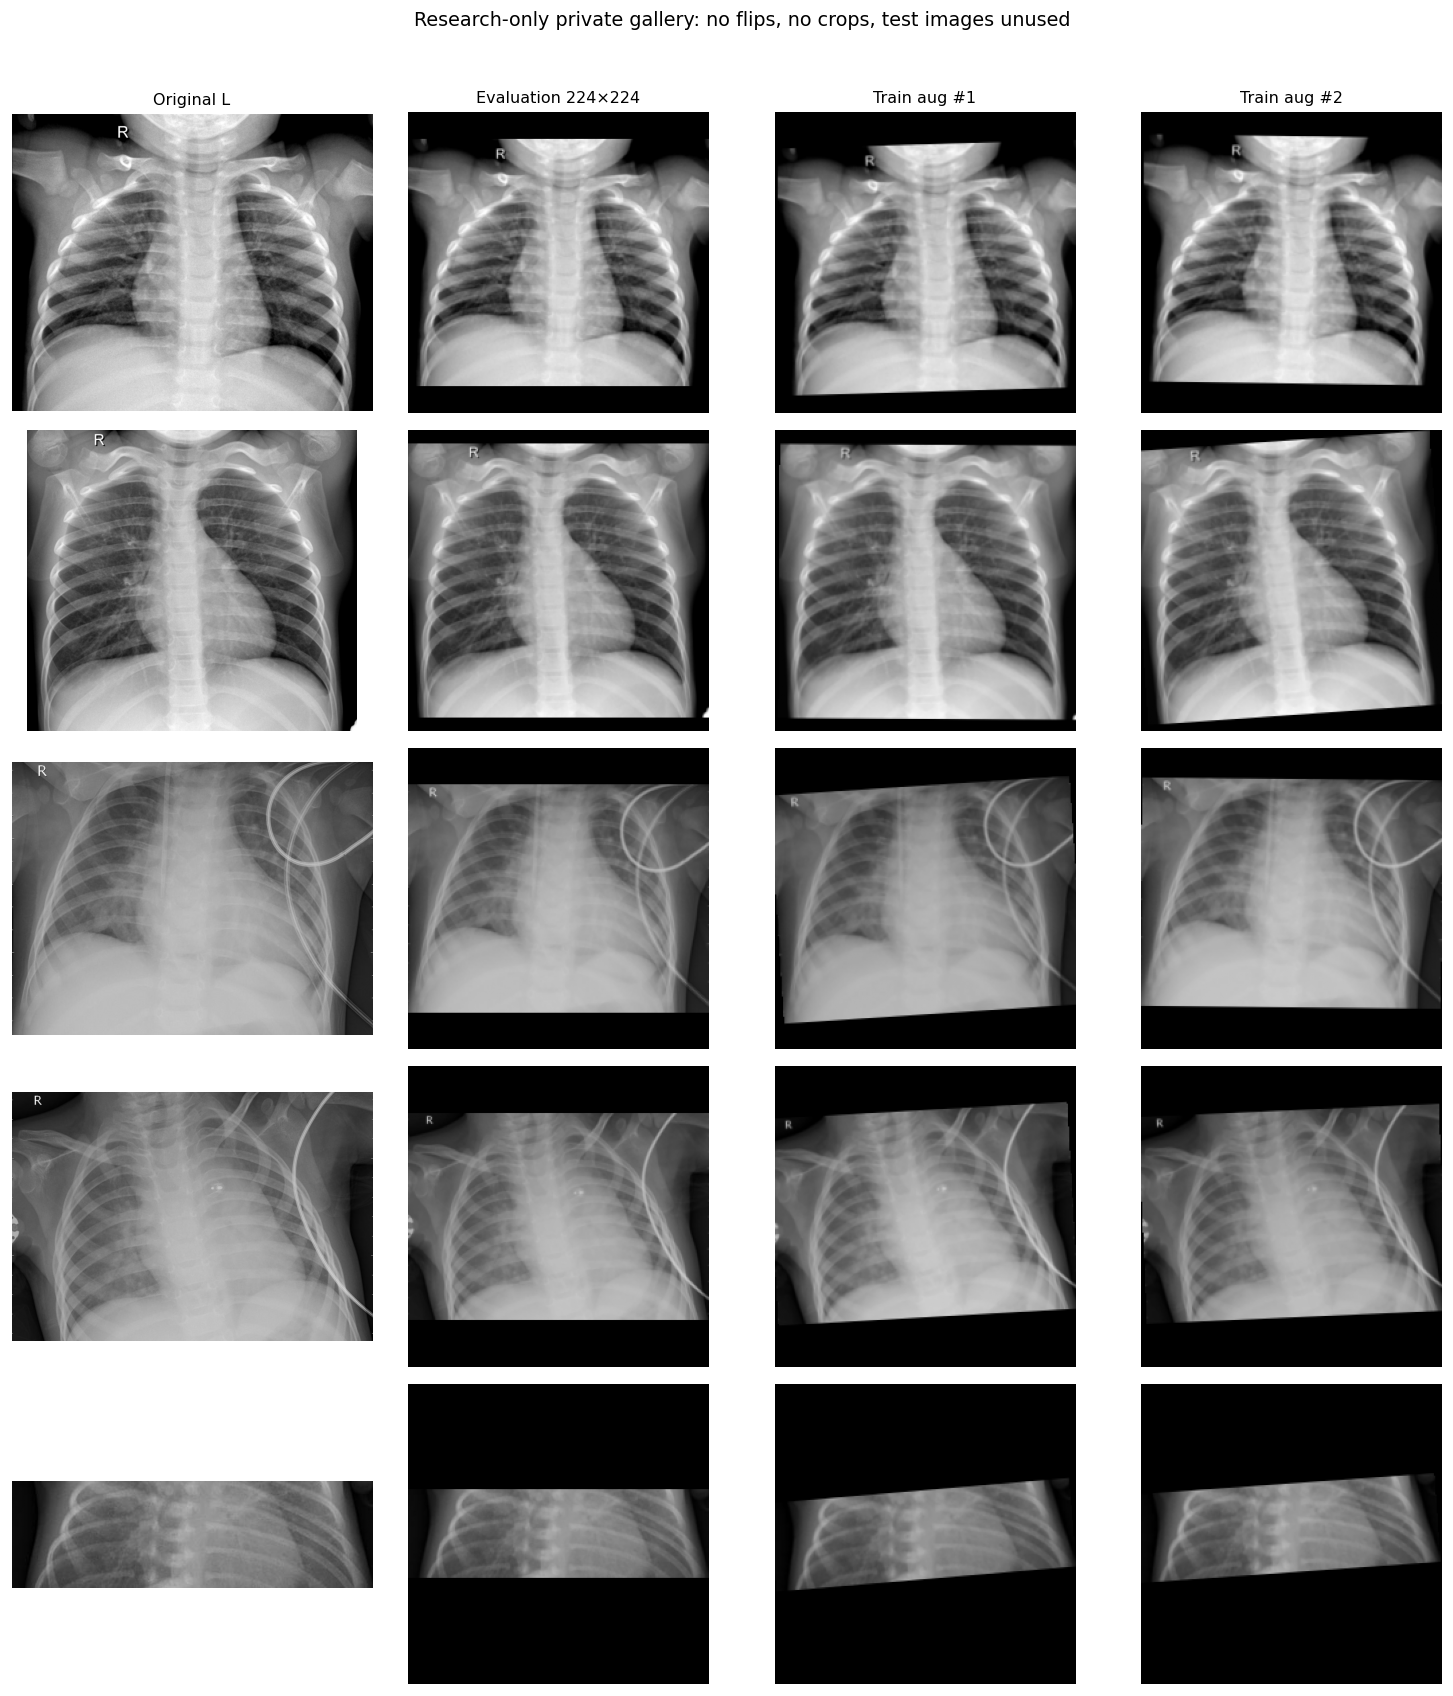

RGB source conversion consistent: True | RGB training images: 283


In [9]:
preview_rows = []
for label in ('NORMAL','PNEUMONIA'):
    subset = profile.loc[profile.label==label]
    if not subset.empty:
        preview_rows.extend(subset.sample(n=min(2,len(subset)),random_state=SEED).to_dict('records'))

# Optional geometry edge cases, not automatically excluded from future training.
extreme = profile.loc[profile.extreme_aspect_review_flag]
if not extreme.empty:
    existing = {r['relative_path'] for r in preview_rows}
    for row in extreme.sort_values('padding_fraction',ascending=False).to_dict('records'):
        if row['relative_path'] not in existing:
            preview_rows.append(row)
            break

train_preview_transform = p.PneumoPreprocessor(CFG,mode='train',rng=random.Random(SEED+17))
fig,axes = plt.subplots(len(preview_rows),4, figsize=(13,max(3,3*len(preview_rows))),
                        squeeze=False)
for i,row in enumerate(preview_rows):
    with open_image_bytes(row['relative_path']) as h:
        with Image.open(h) as im:
            original = p.decode_grayscale(im)
    deterministic = eval_transform(original)
    a1 = train_preview_transform(original)
    a2 = train_preview_transform(original)
    for j,arr in enumerate((np.asarray(original),
                             p.denormalize_grayscale(deterministic,CFG),
                             p.denormalize_grayscale(a1,CFG),
                             p.denormalize_grayscale(a2,CFG))):
        axes[i,j].imshow(arr,cmap='gray',vmin=0,vmax=255)
        axes[i,j].axis('off')
    axes[i,0].set_ylabel(row['label']+' (train)',fontsize=9)
for j,title in enumerate(('Original L','Evaluation 224×224','Train aug #1','Train aug #2')):
    axes[0,j].set_title(title,fontsize=10)
fig.suptitle('Research-only private gallery: no flips, no crops, test images unused',fontsize=12)
fig.tight_layout(rect=(0,0,1,0.965))
private_gallery_path = PRIVATE_DIR/'phase3_transform_gallery_PRIVATE.png'
fig.savefig(private_gallery_path,dpi=160,bbox_inches='tight')
plt.show()
plt.close(fig)

# Check an RGB training source explicitly if one exists.
rgb_rows = profile.loc[profile.native_mode.eq('RGB')]
rgb_check_pass = True
if not rgb_rows.empty:
    r = rgb_rows.iloc[0]
    with open_image_bytes(r.relative_path) as h:
        with Image.open(h) as im:
            src = im.copy()
    from_rgb = eval_transform(src)
    from_converted_gray = eval_transform(p.decode_grayscale(src))
    rgb_check_pass = bool(torch.equal(from_rgb, from_converted_gray))
print('RGB source conversion consistent:',rgb_check_pass,
      '| RGB training images:',len(rgb_rows))

## 9 · Figures: padding, transformed intensities and quality gates

These are aggregate charts derived only from training images. Any increase in label-correlated padding is a **future robustness concern**; it does not justify label-specific transformations or automatic image deletion.

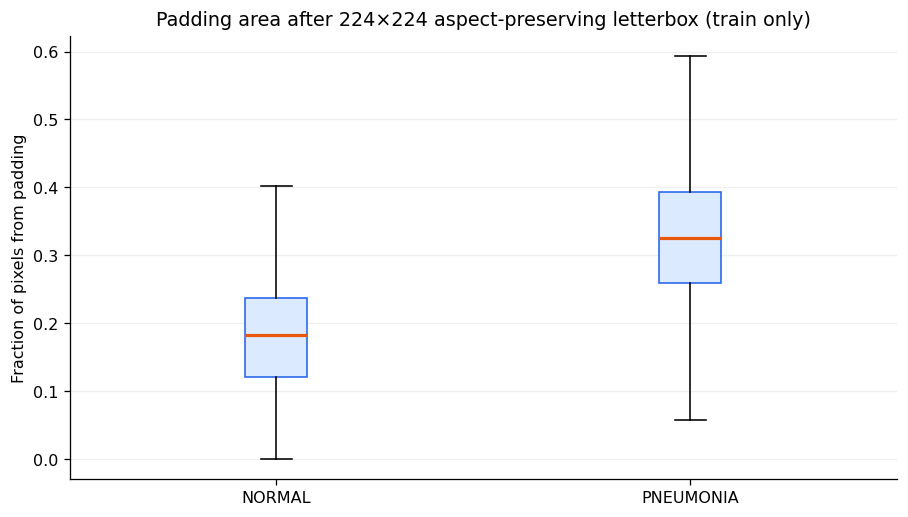

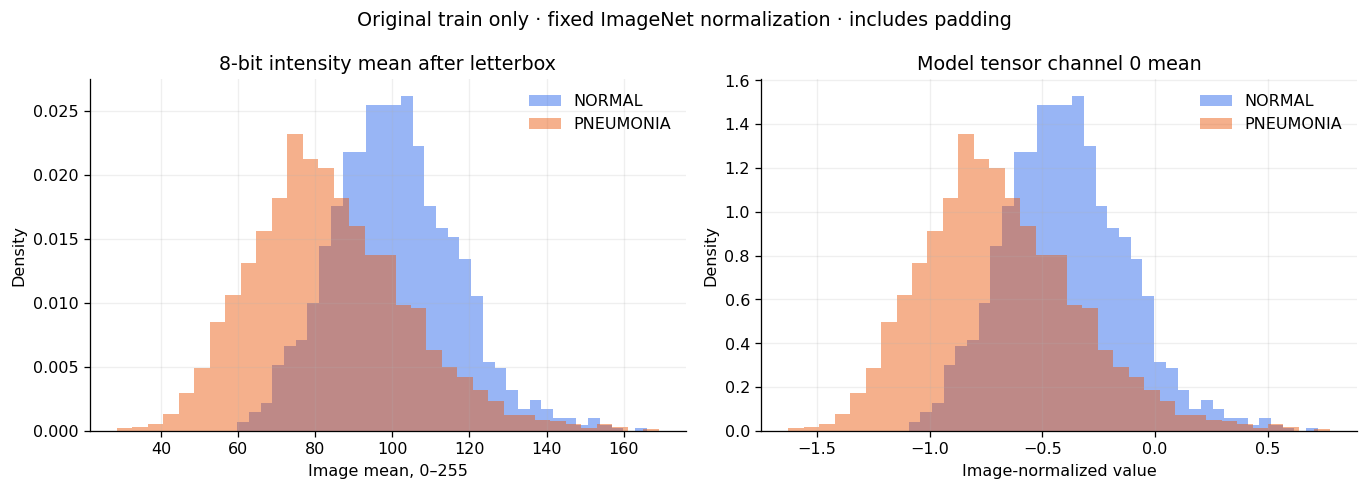

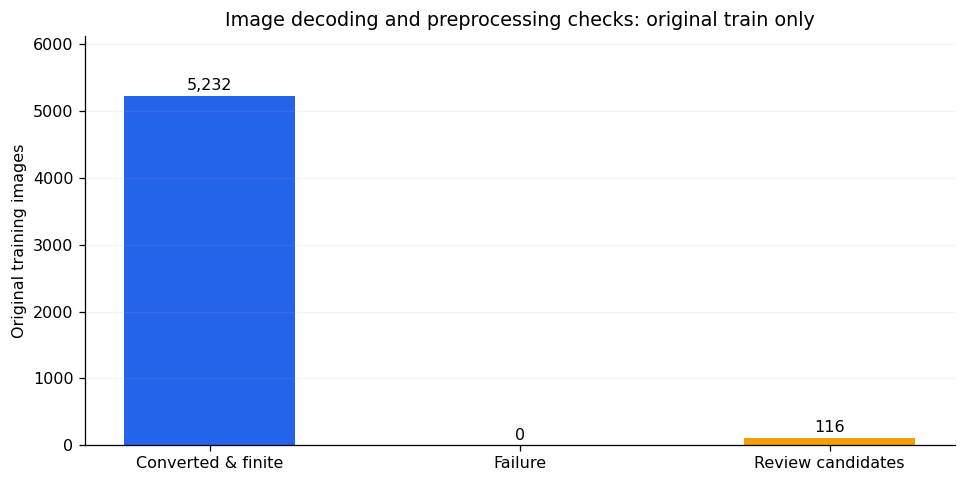

In [10]:
fig,ax = plt.subplots(figsize=(8,4.6))
series = [profile.loc[profile.label==lab,'padding_fraction'].to_numpy() for lab in ('NORMAL','PNEUMONIA')]
ax.boxplot(series,tick_labels=['NORMAL','PNEUMONIA'],showfliers=False,patch_artist=True,
           boxprops=dict(facecolor='#dbeafe',edgecolor='#2563eb'),
           medianprops=dict(color='#ea580c',linewidth=2))
ax.set_ylabel('Fraction of pixels from padding')
ax.set_title('Padding area after 224×224 aspect-preserving letterbox (train only)')
ax.grid(axis='y',alpha=0.2)
fig.tight_layout()
fig.savefig(FIG_DIR/'phase3_01_padding_by_class.png',dpi=170,bbox_inches='tight')
plt.show();plt.close(fig)

fig,axes = plt.subplots(1,2,figsize=(12,4.3))
for label, color in (('NORMAL','#2563eb'),('PNEUMONIA','#ea580c')):
    frame = profile.loc[profile.label==label]
    axes[0].hist(frame.pixel_mean_8bit.to_numpy(),bins=35,alpha=.47,density=True,
                 label=label,color=color)
    axes[1].hist(frame.normalized_ch0_mean.to_numpy(),bins=35,alpha=.47,density=True,
                 label=label,color=color)
axes[0].set_title('8-bit intensity mean after letterbox')
axes[0].set_xlabel('Image mean, 0–255');axes[0].set_ylabel('Density')
axes[1].set_title('Model tensor channel 0 mean')
axes[1].set_xlabel('Image-normalized value');axes[1].set_ylabel('Density')
for ax in axes:
    ax.legend(frameon=False)
    ax.grid(alpha=.2)
fig.suptitle('Original train only · fixed ImageNet normalization · includes padding',fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR/'phase3_02_train_transform_distribution.png',dpi=170,bbox_inches='tight')
plt.show();plt.close(fig)

fig,ax=plt.subplots(figsize=(8.5,4.3))
barlabels=['Converted & finite','Failure','Review candidates']
barvalues=[len(profile),len(failures),int(profile.review_candidate.sum())]
colors=['#2563eb','#dc2626','#f59e0b']
bars=ax.bar(barlabels,barvalues,color=colors,width=0.55)
for bar,value in zip(bars,barvalues):
    ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+max(len(profile)*.008,0.1),
            f'{value:,}',ha='center',va='bottom',fontsize=10)
ax.set_ylabel('Original training images')
ax.set_ylim(0,max(1,len(profile))*1.17)
ax.set_title('Image decoding and preprocessing checks: original train only')
ax.grid(axis='y',alpha=.15)
fig.tight_layout()
fig.savefig(FIG_DIR/'phase3_03_processing_checks.png',dpi=170,bbox_inches='tight')
plt.show();plt.close(fig)

## 10 · Reproducible contract, training-readiness distinction and machine-readable results

This report records decisions **and their limits**. The preprocessing contract is a software interface, not a substitute for leakage-aware splitting. Preprocessing tests can pass even while the future training approval remains blocked.

In [11]:
from hashlib import sha256

module_sha = sha256((SRC_DIR/'transforms.py').read_bytes()).hexdigest()
config_sha = sha256((CONF_DIR/'preprocessing.json').read_bytes()).hexdigest()
fixture_ref = np.load(FIXTURE_DIR/'reference_eval_tensor.npy', allow_pickle=False)
fixture_now = eval_transform(FIXTURE_DIR/'reference_synthetic.png').numpy()
fixture_parity = bool(np.allclose(fixture_now, fixture_ref, atol=1e-6, rtol=0))
repeat_parity = bool(torch.equal(
    eval_transform(FIXTURE_DIR/'reference_synthetic.png'),
    eval_transform(FIXTURE_DIR/'reference_synthetic.png')))

checks = {
    'source_counts_match_phase2_reference':len(count_mismatches)==0,
    'all_source_labels_known':unknown_rows==0,
    'both_original_train_classes_present':{'NORMAL','PNEUMONIA'}.issubset(set(train_df.label)),
    'no_new_validation_split_created':True,
    'all_original_train_images_transformed':len(profile)==len(train_df) and len(failures)==0,
    'source_modes_are_expected_L_or_RGB':set(profile.native_mode).issubset({'L','RGB'}),
    'all_tensor_outputs_finite':True,  # an invalid tensor would be recorded as a failure
    'unit_tests_passed':unit_tests_pass,
    'fixture_numerical_parity':fixture_parity,
    'evaluation_repeatability':repeat_parity,
    'rgb_conversion_parity':rgb_check_pass,
    'train_only_gallery_created':private_gallery_path.is_file(),
    'aggregate_figures_created':len(list(FIG_DIR.glob('phase3_*.png')))>=3,
    'source_code_and_config_exported':(SRC_DIR/'transforms.py').is_file() and (CONF_DIR/'preprocessing.json').is_file(),
}
preprocessing_gate = 'PASS_FOR_SPLIT_REVIEW_AND_NEXT_PHASE_PREPARATION' if all(checks.values()) else 'NEEDS_REVIEW'
training_gate = 'BLOCKED_PENDING_PATIENT_DUPLICATE_AND_VALIDATION_SPLIT_REVIEW'

warnings_out=[
    'Source numeric filename tokens are NOT verified patient IDs; train/validation grouping remains unresolved.',
    'Prior exact duplicates and cross-split perceptual similarity candidates require a documented review.',
    'No validation partition is created in this notebook; original test is locked.',
    'Padding, encoding and size can correlate with class; monitor shortcut learning during modeling.',
    'Fixed ImageNet-1K statistics assume ImageNet-pretrained 3-channel DenseNet121; reconsider for a scratch-trained architecture.',
    'Preprocessing output is not a clinical model and has not been externally validated.',
]
if count_mismatches:
    warnings_out.insert(0,'SOURCE COUNT MISMATCH: '+'; '.join(count_mismatches))
if len(failures):
    warnings_out.insert(0,f'{len(failures)} original train image(s) failed preprocessing. See private failure CSV.')
if not unit_tests_pass:
    warnings_out.insert(0,'Unit tests failed: inspect preprocessing_unit_tests.txt.')

summary = {
    'project':'PneumoLens','github_phase':'Phase 3 - Preprocessing',
    'executed_at_utc':datetime.now(timezone.utc).isoformat(),
    'input_source':str(SOURCE['path']),'input_type':SOURCE['kind'],
    'input_zip_prefix':SOURCE['prefix'],
    'expected_original_source_counts':{f'{a}/{b}':n for (a,b),n in EXPECTED.items()},
    'observed_original_source_counts':{f'{a}/{b}':int(n) for (a,b),n in counts.items()},
    'original_train_images_checked':int(len(train_df)),
    'original_train_images_succeeded':int(len(profile)),
    'original_train_images_failed':int(len(failures)),
    'original_test_pixels_read_for_preprocessing':0,
    'preprocessing_version':CFG['version'],
    'config':CFG,
    'source_sha256':module_sha,
    'config_sha256':config_sha,
    'train_class_wise_statistics':summary_stats.round(5).to_dict(orient='records'),
    'manual_review_candidates_count':int(profile.review_candidate.sum()),
    'class_mean_padding_fraction_absolute_difference':float(class_padding_difference),
    'completion_checks':checks,
    'preprocessing_gate':preprocessing_gate,
    'training_gate':training_gate,
    'warnings':warnings_out,
    'library_versions':{
        'python':sys.version.split()[0],
        'torch':torch.__version__,
        'pillow':Image.__version__,
        'numpy':np.__version__,
        'pandas':pd.__version__,
        'matplotlib':matplotlib.__version__,
    },
}
(PHASE_DIR/'preprocessing_summary.json').write_text(
    json.dumps(summary,indent=2,ensure_ascii=False)+'\n',encoding='utf-8')
print('PHASE 3 PREPROCESSING:',preprocessing_gate)
print('TRAINING APPROVAL:',training_gate)
if not all(checks.values()):
    print('FAILED CHECKS:',[name for name,ok in checks.items() if not ok])

PHASE 3 PREPROCESSING: PASS_FOR_SPLIT_REVIEW_AND_NEXT_PHASE_PREPARATION
TRAINING APPROVAL: BLOCKED_PENDING_PATIENT_DUPLICATE_AND_VALIDATION_SPLIT_REVIEW


In [12]:
report = [
    '# PneumoLens — Phase 3: Image preprocessing',
    '',
    f'**Engineering gate:** {preprocessing_gate}  ',
    f'**Training gate:** {training_gate}  ',
    f'**Date (UTC):** {summary["executed_at_utc"]}  ',
    f'**Source:** `{SOURCE["path"]}`  ',
    '',
    '## 1. Preprocessing contract',
    '- Task: folder-labeled pediatric NORMAL (0) vs PNEUMONIA (1), research only.',
    '- Image decode: Pillow with EXIF orientation; deterministically convert L/RGB inputs to 8-bit grayscale.',
    '- Geometry: 224×224 bilinear aspect-preserving resize and centered zero padding; no crop.',
    '- Channels: replicate one grayscale channel three times for ImageNet-pretrained DenseNet121.',
    '- Normalization: fixed ImageNet-1K mean (0.485, 0.456, 0.406) and std (0.229, 0.224, 0.225).',
    '- Training augmentation: ±5° rotation, ±2% translation, ±5% brightness and contrast only.',
    '- Evaluation/inference augmentation: none. Horizontal/vertical flips and random crops are prohibited.',
    '- ImageNet pretraining on generic natural images is external pretraining, not an additional chest X-ray dataset.',
    '',
    '## 2. Data and transform verification',
    f'- Original train images: **{len(train_df):,}**; successfully transformed: **{len(profile):,}**; failures: **{len(failures)}**.',
    f'- Original test pixel data accessed for transform design: **0**.',
    f'- Unit tests: **{"PASS" if unit_tests_pass else "FAIL"}**; fixture parity: **{fixture_parity}**; eval repeatability: **{repeat_parity}**.',
    f'- Unusual train-only geometry/contrast review candidates: **{int(profile.review_candidate.sum()):,}** (not exclusions).',
    f'- Class-wise mean padding-fraction difference: **{class_padding_difference:.4f}** (descriptive; possible shortcut risk).',
    '',
    '## 3. File and code identity',
    f'- `src/preprocessing/transforms.py` SHA256: `{module_sha}`',
    f'- `configs/preprocessing.json` SHA256: `{config_sha}`',
    '- The same exported transform must be imported by Kaggle training and the Streamlit inference app.',
    '',
    '## 4. Machine-readable and visual outputs',
    '- Summary: `reports/Phase 3/preprocessing_summary.json`.',
    '- Tables: `reports/tables/phase3_*.csv` (class-level aggregates only).',
    '- Figures: `reports/figures/phase3_*.png` (aggregate figures only).',
    '- Local-only private file-level profiles and radiograph gallery: `data/processed/phase3_*PRIVATE*`.',
    '- Regression fixture and tests: `tests/fixtures/` and `tests/test_preprocessing.py`.',
    '',
    '## 5. Completion checks',
] + [f'- {"PASS" if yes else "FAIL"}: {name.replace("_", " ")}' for name,yes in checks.items()]
report += [
    '', '## 6. Important unresolved methodological issues',
] + [f'- {s}' for s in warnings_out]
report += [
    '', '## 7. Handoff to Phase 4',
    '- Approve leakage-aware train/validation splits and duplicate policies **before training**.',
    '- When approved, calculate loss class weights from that approved training subset only.',
    '- Benchmark the planned DenseNet121 baseline; evaluate sensitivity, specificity, ROC-AUC, PR-AUC and calibration later.',
    '- Always record versioned transform/config hashes with model checkpoints.',
    '',
    '**Research-only limitation:** This pipeline does not establish patient independence, calibration, external validity, lesion localization, or clinical diagnostic safety.',
]
(PHASE_DIR/'preprocessing_report.md').write_text('\n'.join(report)+'\n',encoding='utf-8')
print('Saved audit report and summary.')

Saved audit report and summary.


## 11 · Usage contract for Kaggle training and Streamlit inference

**No duplicated logic:** in the future model-training notebook and Streamlit, import `src.preprocessing.transforms` from the project repository. The same config handles both normal and pneumonia images; it never uses true labels to choose image transformations. Train-only augmentation must never be used on validation, test or uploaded app images.

In [13]:
handoff_doc = r"""# PneumoLens — preprocessing contract

## Installation and usage

Use `src/preprocessing/transforms.py` and `configs/preprocessing.json` from this Phase 3 ZIP
in your GitHub repository. Kaggle training notebooks should import exactly these files
from the repository source, not copy/paste alternative transformations.

```python
from src.preprocessing.transforms import load_config, PneumoPreprocessor
config = load_config('configs/preprocessing.json')
train_transform = PneumoPreprocessor(config, mode='train')  # ONLY approved training subset
inference_transform = PneumoPreprocessor(config, mode='eval')  # validation/test/Streamlit
input_tensor = inference_transform('example_xray.jpg')   # shape [3,224,224]
# For a single image in PyTorch: input_tensor.unsqueeze(0)
```

Do not use `train_transform` on any validation/test or app image. For model training
with multiple DataLoader workers, seed Python's `random` in each worker as well as
the torch worker seeds; always record seed and versions for reproducible experiments.

The pretrained backbones use fixed ImageNet-1K mean/std after luminance conversion
and three-channel replication. Do not replace with Phase 2 raw thumbnail statistics.
Original grayscale should remain available separately for human viewing and Grad-CAM.

## Test locally

```bash
python -m unittest discover -s tests -p "test_preprocessing.py" -v
```

For complete numerical parity, compare output tensors with the included synthetic
reference (`tests/fixtures/reference_eval_tensor.npy`). Pillow version differences
may affect interpolation at the sub-pixel level; record the same Pillow version in
training, testing and inference and explicitly rerun regression tests after upgrades.

## Data integrity limitations

- No validation split has been created or approved.
- Original test images were not used to fit preprocessing decisions.
- Exact duplicate review, cross-split visual similarity and patient-level independence
  remain open from the Phase 1 audit.
- Raw size, color mode and padding correlate with labels; evaluate shortcut behavior.
- Do not commit patient image galleries, private file-level profiles or the dataset.
- Research and educational prototype only; no diagnostic or clinical use.
"""
(DOC_DIR/'preprocessing_contract.md').write_text(handoff_doc,encoding='utf-8')
print('Saved:', DOC_DIR/'preprocessing_contract.md')

Saved: /kaggle/working/pneumolens_phase03/project_files/docs/preprocessing_contract.md


## 12 · Final integrity checks and one-click project ZIP

The final ZIP contains correct relative paths for your Windows project root:

`E:\CODE\Python\ALL Project\Computer Vision\PneumoLens`

It does **not** include any original source X-ray files, any trained checkpoint, or this notebook itself (save it separately to `notebooks/03_Preprocessing.ipynb`).

In [14]:
must_have = [
    SRC_DIR/'transforms.py', CONF_DIR/'preprocessing.json',
    TEST_DIR/'test_preprocessing.py',
    FIXTURE_DIR/'reference_synthetic.png', FIXTURE_DIR/'reference_eval_tensor.npy',
    PHASE_DIR/'preprocessing_report.md', PHASE_DIR/'preprocessing_summary.json',
    PHASE_DIR/'preprocessing_unit_tests.txt',
    TAB_DIR/'phase3_train_transform_summary.csv',
    PRIVATE_DIR/'phase3_train_transform_profile_PRIVATE.csv',
    PRIVATE_DIR/'phase3_transform_gallery_PRIVATE.png',
    DOC_DIR/'preprocessing_contract.md',
]
missing=[str(x) for x in must_have if not x.is_file()]
if missing:
    raise RuntimeError('Required Phase 3 outputs absent: '+str(missing))

zip_path = WORK_DIR/'PneumoLens_Phase3_Preprocessing_Outputs.zip'
files_to_package = sorted(p for p in PROJECT_ROOT.rglob('*')
                          if p.is_file() and '__pycache__' not in p.parts
                          and p.suffix not in ('.pyc', '.pyo') )
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for file in files_to_package:
        z.write(file,arcname=file.relative_to(PROJECT_ROOT).as_posix())
with zipfile.ZipFile(zip_path,'r') as z:
    bad=z.testzip()
    if bad:
        raise IOError(f'Corrupt ZIP member: {bad}')
    if len(z.namelist()) != len(files_to_package):
        raise IOError('ZIP member count mismatch')

if ARCHIVE is not None:
    ARCHIVE.close()
print('\n'+'='*60)
print('PNEUMOLENS PHASE 3 — EXPORT COMPLETE')
print('='*60)
print('Preprocessing gate:', preprocessing_gate)
print('Training gate:', training_gate)
print('Full original train checks:', len(profile),'/',len(train_df))
print('Unit tests:', 'PASS' if unit_tests_pass else 'FAIL')
print('Exported files:',len(files_to_package),'| ZIP size:',round(zip_path.stat().st_size/1024/1024,2),'MiB')
print('ZIP:',zip_path)
print('Extract into E:\\CODE\\Python\\ALL Project\\Computer Vision\\PneumoLens')
print('Save notebook separately as notebooks/03_Preprocessing.ipynb')
print('Commit src/, configs/, tests/, docs/, reports/; keep data/processed/ PRIVATE.')
display(FileLink(str(zip_path)))


PNEUMOLENS PHASE 3 — EXPORT COMPLETE
Preprocessing gate: PASS_FOR_SPLIT_REVIEW_AND_NEXT_PHASE_PREPARATION
Training gate: BLOCKED_PENDING_PATIENT_DUPLICATE_AND_VALIDATION_SPLIT_REVIEW
Full original train checks: 5232 / 5232
Unit tests: PASS
Exported files: 22 | ZIP size: 2.04 MiB
ZIP: /kaggle/working/pneumolens_phase03/PneumoLens_Phase3_Preprocessing_Outputs.zip
Extract into E:\CODE\Python\ALL Project\Computer Vision\PneumoLens
Save notebook separately as notebooks/03_Preprocessing.ipynb
Commit src/, configs/, tests/, docs/, reports/; keep data/processed/ PRIVATE.


/kaggle/working/pneumolens_phase03/PneumoLens_Phase3_Preprocessing_Outputs.zip